In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold,GridSearchCV
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [5]:
# 데이터 불러오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)
# fish.info()
# fish.describe()
fish.columns
data = fish.drop(columns=['Species']).values
label = fish['Species'].values
data,label


(array([[2.42000e+02, 2.54000e+01, 3.00000e+01, 1.15200e+01, 4.02000e+00],
        [2.90000e+02, 2.63000e+01, 3.12000e+01, 1.24800e+01, 4.30560e+00],
        [3.40000e+02, 2.65000e+01, 3.11000e+01, 1.23778e+01, 4.69610e+00],
        [3.63000e+02, 2.90000e+01, 3.35000e+01, 1.27300e+01, 4.45550e+00],
        [4.30000e+02, 2.90000e+01, 3.40000e+01, 1.24440e+01, 5.13400e+00],
        [4.50000e+02, 2.97000e+01, 3.47000e+01, 1.36024e+01, 4.92740e+00],
        [5.00000e+02, 2.97000e+01, 3.45000e+01, 1.41795e+01, 5.27850e+00],
        [3.90000e+02, 3.00000e+01, 3.50000e+01, 1.26700e+01, 4.69000e+00],
        [4.50000e+02, 3.00000e+01, 3.51000e+01, 1.40049e+01, 4.84380e+00],
        [5.00000e+02, 3.07000e+01, 3.62000e+01, 1.42266e+01, 4.95940e+00],
        [4.75000e+02, 3.10000e+01, 3.62000e+01, 1.42628e+01, 5.10420e+00],
        [5.00000e+02, 3.10000e+01, 3.62000e+01, 1.43714e+01, 4.81460e+00],
        [5.00000e+02, 3.15000e+01, 3.64000e+01, 1.37592e+01, 4.36800e+00],
        [3.40000e+02, 3.2

In [6]:
# 데이터 분리

train_data,test_data,train_label,test_label = train_test_split(data,label)

In [7]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [8]:
# 데이터 학습
cc = [0.0001,0.001,0.01,0.1,1,10,20,100]
train_score = []
test_score = []
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))


In [14]:
score = lr.score(train_scaled,train_label)
score1 = lr.score(test_scaled,test_label)
score,score1

(0.9747899159663865, 0.925)

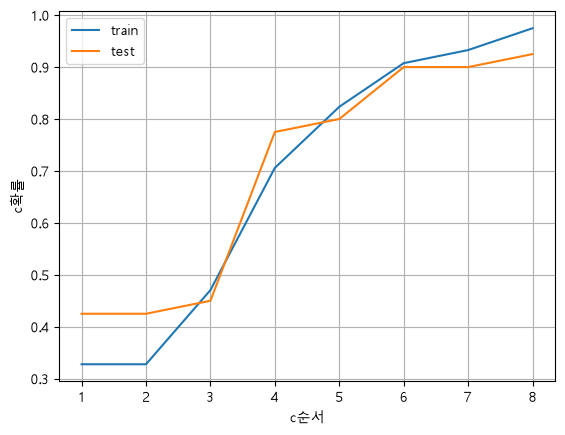

In [10]:
list1 = list(range(1,9))
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('c순서')
plt.ylabel('c확률')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [13]:
# 실제 입력받아 예측하시오
predict = lr.predict(test_scaled[:1])
print('분류생선:',predict)
proba = lr.predict_proba(test_scaled[:1])
proba = proba.max()
print('확률:',proba)
decisions = lr.decision_function(train_scaled[:1])
soft1 = softmax(decisions,axis=1)
print(np.round(soft1,decimals=3))
print(lr.classes_)

분류생선: ['Smelt']
확률: 0.9856189957569319
[[0.    0.016 0.028 0.001 0.945 0.001 0.009]]
['Bream' 'Parkki' 'Perch' 'Pike' 'Roach' 'Smelt' 'Whitefish']


In [ ]:
# 새로운 데이터를 분류
# 1. 정규화
# 2. 데이터 predict